# Projet 2 — Sales Prediction : prévoir les ventes à partir des budgets publicitaires

**Objectif métier.** Une entreprise répartit un budget publicitaire entre trois canaux (**TV, Radio, Presse**).
On veut (1) **prévoir les ventes** pour un budget donné, (2) **mesurer l'impact** de chaque canal et (3) **recommander une répartition** plus rentable.

**Données** : `Advertising.csv` — 200 campagnes. Budgets en *milliers de dollars*, ventes en *milliers d'unités* (unités du jeu de données d'origine).

**Cadrage du problème (important).**
- Le fichier ne contient **aucune date** : on ne peut donc pas faire de série temporelle. Le bon outil est la **régression** : « pour tel budget, quelles ventes ? ». Les « ventes futures » sont des prévisions pour des budgets *planifiés*.
- Le fichier ne contient pas de colonne « segment cible » : les **plateformes** sont les trois canaux (TV, Radio, Presse).

**Plan du notebook** : 1. Mise en place · 2. Chargement · 3. Nettoyage · 4. Analyse univariée · 5. Analyse bivariée · 6. Découpage train/test · 7. Modèle de base et statistiques · 8. Sélection de variables · 9. Transformation (feature engineering) · 10. Comparaison de modèles · 11. Modèle final · 12. Analyse d'impact et recommandations · 13. Passage en production.

> **Comment utiliser ce notebook** : exécutez les cellules **une par une** (`Maj + Entrée`) en lisant le commentaire et le résultat avant de passer à la suivante.

## 1. Mise en place

In [1]:
# --- Bibliothèques de base pour manipuler les données et tracer des graphiques ---
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")  # garde la sortie lisible (avertissements non bloquants)

In [2]:
# --- scikit-learn : découpage des données, modèles et mesures de performance ---
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import RepeatedKFold, cross_val_score, learning_curve, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, PolynomialFeatures, StandardScaler

In [3]:
# --- Code du projet (dossier src/) ---
# On réutilise EXACTEMENT les fonctions de production : ce qu'on valide ici est ce qui sera déployé.
from sales_prediction.analysis import (
    marginal_effects,
    ols_summary,
    optimize_budget,
    predict_sales,
    variance_inflation_factors,
    what_if,
)
from sales_prediction.config import load_config
from sales_prediction.features import add_engineered_features, build_pipeline

In [4]:
# --- Réglages d'affichage et constantes du projet ---
pd.set_option("display.precision", 3)         # 3 décimales dans les tableaux
sns.set_theme(style="whitegrid")              # style des graphiques
plt.rcParams["figure.dpi"] = 100

RANDOM_STATE = 42                             # graine : rend les résultats reproductibles
CHANNELS = ["TV", "Radio", "Newspaper"]       # variables explicatives (budgets)
TARGET = "Sales"                              # variable à prédire
COLORS = {"TV": "#355c9a", "Radio": "#e4572e", "Newspaper": "#8b95a1", "Sales": "#2a9d8f"}

## 2. Chargement et premier contact avec les données
On commence toujours par **regarder** les données brutes, sans rien modifier.

In [5]:
# Lecture du fichier brut (le notebook est dans notebooks/, d'où le "../")
df_raw = pd.read_csv("../data/raw/Advertising.csv")
df_raw.head()  # les 5 premières lignes

,Unnamed: 0,TV,Radio,Newspaper,Sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


In [6]:
# Dimensions (lignes, colonnes) et types des colonnes
print("Dimensions :", df_raw.shape)
df_raw.info()

Dimensions : (200, 5)
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  200 non-null    int64  
 1   TV          200 non-null    float64
 2   Radio       200 non-null    float64
 3   Newspaper   200 non-null    float64
 4   Sales       200 non-null    float64
dtypes: float64(4), int64(1)
memory usage: 7.9 KB


**Observations** : 200 lignes, 5 colonnes, toutes numériques, aucune valeur manquante apparente.
La colonne `Unnamed: 0` est suspecte : c'est probablement un simple numéro de ligne exporté par erreur. Vérifions.

In [7]:
# Si la colonne vaut exactement 1, 2, 3, ... 200, c'est un index sans valeur analytique
(df_raw["Unnamed: 0"] == np.arange(1, len(df_raw) + 1)).all()

np.True_

## 3. Nettoyage des données (data cleaning)
Quatre contrôles : colonnes inutiles, valeurs manquantes, doublons, valeurs impossibles.

In [8]:
# 1) Suppression de la colonne d'index (inutile, et dangereuse : un modèle pourrait « apprendre » le numéro de ligne)
df = df_raw.drop(columns="Unnamed: 0").copy()
df.columns.tolist()

['TV', 'Radio', 'Newspaper', 'Sales']

In [9]:
# 2) Valeurs manquantes par colonne
df.isna().sum()

TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

In [10]:
# 3) Lignes en double (une campagne comptée deux fois fausserait les statistiques)
print("Doublons :", df.duplicated().sum())

Doublons : 0


In [11]:
# 4) Valeurs impossibles : un budget ou des ventes négatifs n'ont pas de sens
(df < 0).sum()

TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

In [12]:
# Résumé statistique : count, moyenne, écart-type, min, quartiles (25/50/75 %), max
df.describe().T

,count,mean,std,min,25%,50%,75%,max
TV,200.0,147.042,85.854,0.7,74.375,149.75,218.825,296.4
Radio,200.0,23.264,14.847,0.0,9.975,22.90,36.525,49.6
Newspaper,200.0,30.554,21.779,0.3,12.750,25.75,45.100,114.0
Sales,200.0,14.023,5.217,1.6,10.375,12.90,17.400,27.0


**Comment lire ce tableau**
- **TV** : moyenne ≈ médiane (≈ 147 vs 150) → distribution à peu près symétrique, budgets de 0,7 à 296 k$.
- **Radio** : minimum à **0** → certaines campagnes n'ont aucun budget radio.
- **Newspaper** : moyenne (30,6) > médiane (25,8) et maximum de 114 très loin du 75e centile (45) → distribution **asymétrique à droite**, avec des valeurs extrêmes.
- **Sales** : de 1,6 à 27 (k unités), moyenne ≈ 14.

In [13]:
# Contrôle de cohérence : la fonction de nettoyage du projet (src/) donne-t-elle exactement le même résultat ?
from sales_prediction.data import clean

config = load_config()
assert clean(df_raw, config).equals(df), "Le nettoyage du notebook diffère de celui du projet"
print("OK : le nettoyage du notebook = le nettoyage de production")

OK : le nettoyage du notebook = le nettoyage de production


## 4. Analyse univariée — étudier chaque variable séparément
Pour chaque variable : forme de la distribution, asymétrie, valeurs extrêmes.

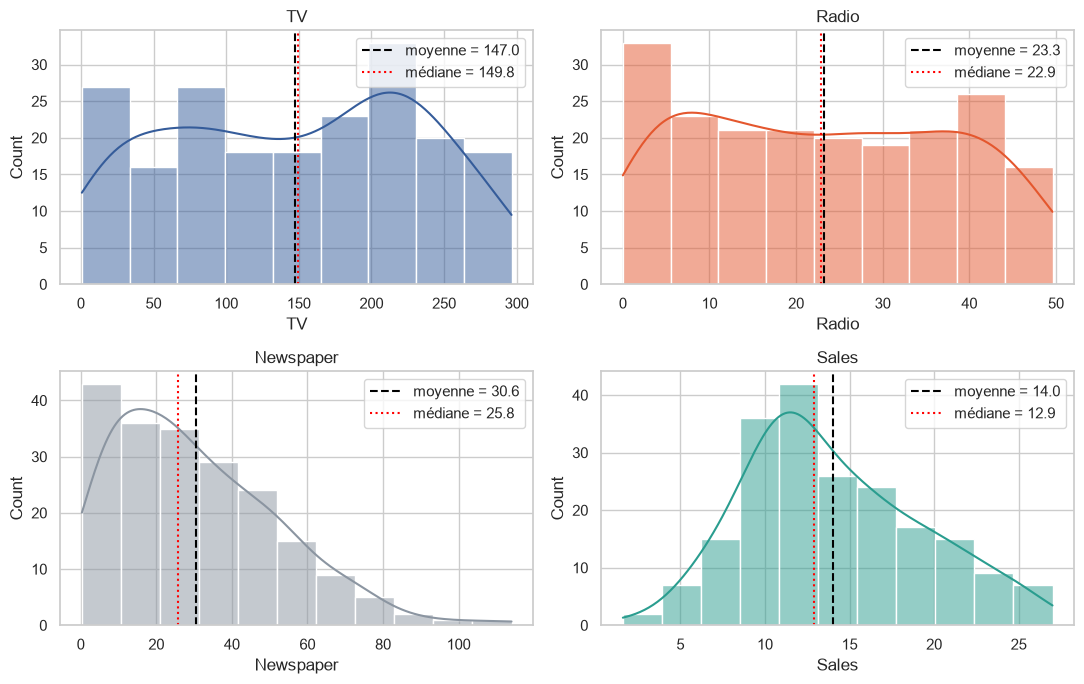

In [14]:
# Histogrammes + courbe de densité (KDE). Trait noir = moyenne, trait rouge = médiane.
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, col in zip(axes.ravel(), df.columns):
    sns.histplot(df[col], kde=True, ax=ax, color=COLORS[col])
    ax.axvline(df[col].mean(), color="black", linestyle="--", label=f"moyenne = {df[col].mean():.1f}")
    ax.axvline(df[col].median(), color="red", linestyle=":", label=f"médiane = {df[col].median():.1f}")
    ax.set_title(col)
    ax.legend()
plt.tight_layout()
plt.show()

In [15]:
# Asymétrie (skewness) : 0 = symétrique, > 0 = queue à droite, < 0 = queue à gauche
# Aplatissement (kurtosis) : > 0 = queues plus lourdes qu'une loi normale
df.agg(["skew", "kurt"]).T

,skew,kurt
TV,-0.070,-1.226
Radio,0.094,-1.260
Newspaper,0.895,0.650
Sales,0.408,-0.409


**Lecture** : seule **Newspaper** est nettement asymétrique (skew ≈ 0,9). TV et Sales sont proches de la symétrie.
Une régression linéaire **ne demande pas** que les variables explicatives soient normales (elle s'intéresse aux *résidus*, vus plus loin) : il n'y a donc pas d'urgence à transformer Newspaper.

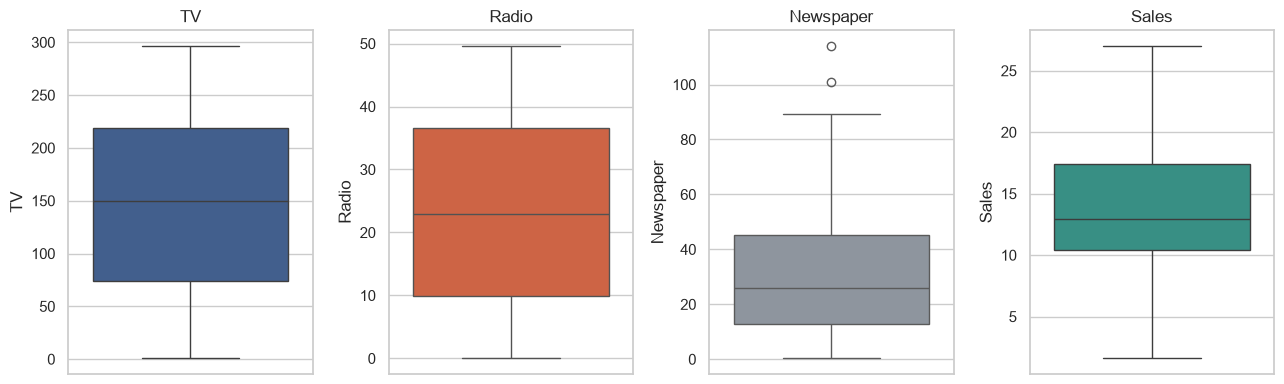

In [16]:
# Boîtes à moustaches : les points au-delà des « moustaches » sont des valeurs atypiques (règle 1,5 × IQR)
fig, axes = plt.subplots(1, 4, figsize=(13, 4))
for ax, col in zip(axes, df.columns):
    sns.boxplot(y=df[col], ax=ax, color=COLORS[col])
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [17]:
# Comptage des valeurs atypiques par la règle de l'IQR (écart interquartile)
def count_iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())

df.apply(count_iqr_outliers).rename("valeurs atypiques")

TV           0
Radio        0
Newspaper    2
Sales        0
Name: valeurs atypiques, dtype: int64

In [18]:
# Quelles sont ces campagnes presse atypiques ?
q1, q3 = df["Newspaper"].quantile([0.25, 0.75])
df[df["Newspaper"] > q3 + 1.5 * (q3 - q1)]

,TV,Radio,Newspaper,Sales
16,67.8,36.6,114.0,12.5
101,296.4,36.3,100.9,23.8


**Décision** : seules **2 campagnes** ont un budget presse atypique (> 93 k$). Ce sont des budgets **réels et plausibles**, pas des erreurs de saisie → on les **conserve**. Supprimer des points sans raison métier fait perdre de l'information.

In [19]:
# Test de normalité de Shapiro-Wilk : H0 = « la variable suit une loi normale ». p < 0,05 → on rejette H0.
pd.DataFrame(
    {col: {"statistique W": stats.shapiro(df[col]).statistic, "p-value": stats.shapiro(df[col]).pvalue} for col in df.columns}
).T

,statistique W,p-value
TV,0.950,1.693e-06
Radio,0.944,5.198e-07
Newspaper,0.936,1.127e-07
Sales,0.976,1.683e-03


**Lecture** : les quatre p-values sont très inférieures à 0,05 → **aucune variable n'est strictement normale**. TV et Radio sont plutôt « plates » (kurtosis ≈ −1,2 : budgets répartis assez uniformément) et Newspaper est étirée à droite. Ce n'est **pas un problème** : la régression exige la normalité des *résidus* (section 7), pas celle des variables explicatives. De plus, avec 200 observations, ce test est très sensible aux petits écarts.

## 5. Analyse bivariée — comment chaque canal est-il lié aux ventes ?

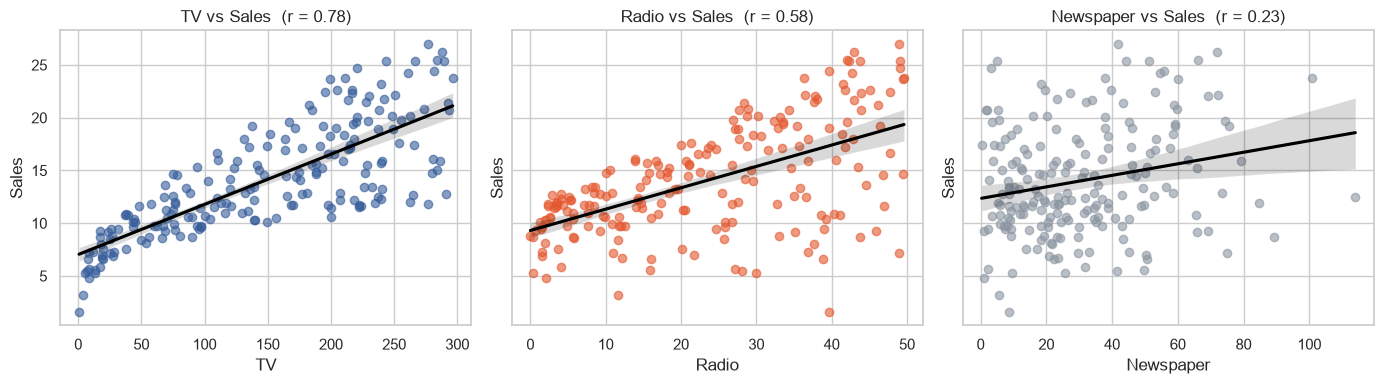

In [20]:
# Nuages de points « canal vs ventes » avec droite de régression et corrélation de Pearson (r)
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, ch in zip(axes, CHANNELS):
    sns.regplot(data=df, x=ch, y=TARGET, ax=ax, color=COLORS[ch], scatter_kws={"alpha": 0.6}, line_kws={"color": "black"})
    ax.set_title(f"{ch} vs {TARGET}  (r = {df[ch].corr(df[TARGET]):.2f})")
plt.tight_layout()
plt.show()

In [21]:
# Matrice de corrélation de Pearson (de -1 à +1) : mesure la force de la relation LINÉAIRE entre deux variables
corr = df.corr()
corr

,TV,Radio,Newspaper,Sales
TV,1.000,0.055,0.057,0.782
Radio,0.055,1.000,0.354,0.576
Newspaper,0.057,0.354,1.000,0.228
Sales,0.782,0.576,0.228,1.000


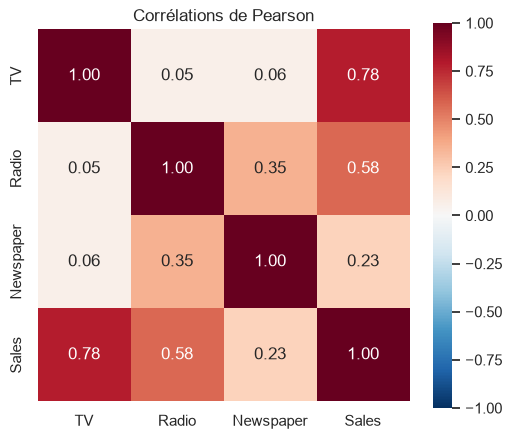

In [22]:
# Même matrice en carte de chaleur
plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True)
plt.title("Corrélations de Pearson")
plt.show()

**Lecture**
- **TV ↔ Sales : 0,78** → la relation la plus forte.
- **Radio ↔ Sales : 0,58** → forte également.
- **Newspaper ↔ Sales : 0,23** → faible… mais **Newspaper ↔ Radio : 0,35**. Les campagnes qui investissent en presse investissent aussi en radio. La presse pourrait donc sembler « utile » **uniquement parce qu'elle voyage avec la radio**. Testons cette hypothèse.

In [23]:
# Corrélation robuste aux valeurs extrêmes (Spearman = corrélation sur les rangs) : confirme-t-elle le constat ?
df.corr(method="spearman")[TARGET]

TV           0.801
Radio        0.554
Newspaper    0.195
Sales        1.000
Name: Sales, dtype: float64

In [24]:
# CORRÉLATION PARTIELLE Newspaper–Sales en « contrôlant » Radio :
# on retire de chaque variable la part expliquée par Radio, puis on corrèle ce qui reste.
def residuals_after(variable, control):
    return variable - LinearRegression().fit(control, variable).predict(control)

res_news = residuals_after(df["Newspaper"], df[["Radio"]])
res_sales = residuals_after(df[TARGET], df[["Radio"]])
r_partial, p_partial = stats.pearsonr(res_news, res_sales)

print(f"Corrélation brute     Newspaper–Sales        : {df['Newspaper'].corr(df[TARGET]):.3f}")
print(f"Corrélation partielle Newspaper–Sales | Radio : {r_partial:.3f}  (p = {p_partial:.3f})")

Corrélation brute     Newspaper–Sales        : 0.228
Corrélation partielle Newspaper–Sales | Radio : 0.032  (p = 0.656)


**Conclusion** : une fois l'effet de la radio retiré, la corrélation Newspaper–Sales **tombe à ≈ 0** et n'est plus significative. C'est un cas classique de **variable confondante** : *corrélation ≠ causalité*. La presse n'a pas d'effet propre mesurable ; elle est simplement associée à la radio.

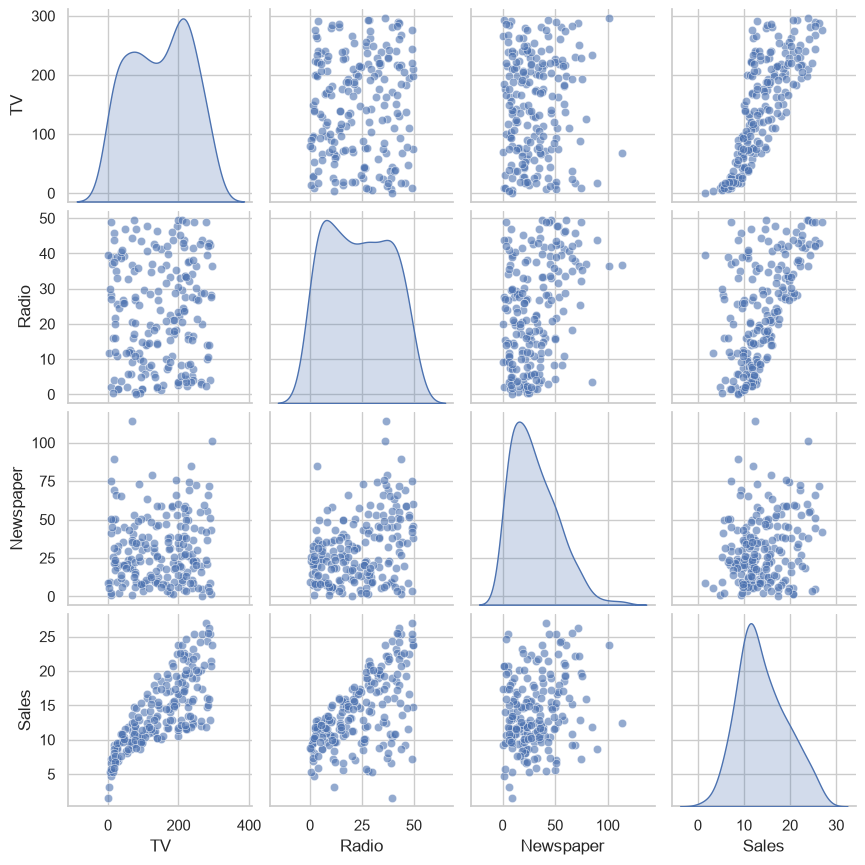

In [25]:
# Vue d'ensemble de toutes les paires de variables
sns.pairplot(df, diag_kind="kde", height=2.2, plot_kws={"alpha": 0.6})
plt.show()

In [26]:
# MULTICOLINÉARITÉ : VIF (Variance Inflation Factor). VIF ≈ 1 = variable indépendante des autres ; > 5 = problème.
variance_inflation_factors(df[CHANNELS])

TV           1.005
Radio        1.145
Newspaper    1.145
Name: VIF, dtype: float64

**Lecture** : tous les VIF sont proches de 1 → les trois budgets sont peu redondants entre eux, les coefficients de régression seront **stables et interprétables**.

### Un indice de synergie
Le nuage `TV vs Sales` est en forme d'**entonnoir** : à budget TV égal, les ventes varient beaucoup. La radio explique-t-elle cette dispersion ?

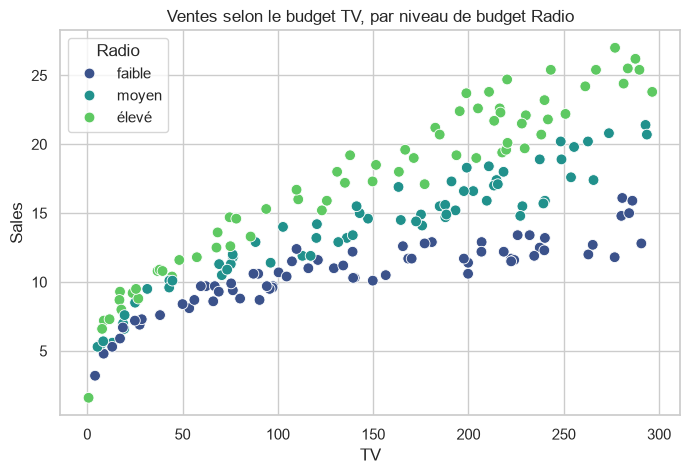

In [27]:
# On colore chaque campagne selon son niveau de budget Radio (tercile : faible / moyen / élevé)
radio_level = pd.qcut(df["Radio"], 3, labels=["faible", "moyen", "élevé"])

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="TV", y=TARGET, hue=radio_level, palette="viridis", s=60)
plt.title("Ventes selon le budget TV, par niveau de budget Radio")
plt.show()

In [28]:
# Ventes moyennes pour chaque combinaison (niveau TV × niveau Radio)
labels = ["faible", "moyen", "élevé"]
levels = pd.DataFrame(
    {
        "TV": pd.qcut(df["TV"], 3, labels=labels),
        "Radio": pd.qcut(df["Radio"], 3, labels=labels),
        "Sales": df[TARGET],
    }
)
pivot = levels.pivot_table(index="TV", columns="Radio", values="Sales", aggfunc="mean", observed=True)
pivot

Radio,faible,moyen,élevé
TV,,,
faible,8.172,9.042,10.396
moyen,11.213,14.564,18.606
élevé,12.995,18.010,22.858


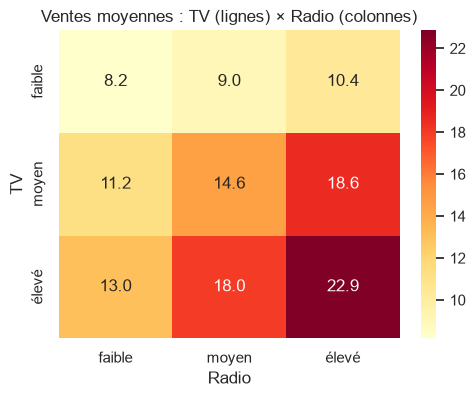

In [29]:
plt.figure(figsize=(5.5, 4))
sns.heatmap(pivot, annot=True, fmt=".1f", cmap="YlOrRd")
plt.title("Ventes moyennes : TV (lignes) × Radio (colonnes)")
plt.show()

**Lecture (très important pour la suite)** : passer d'une radio faible à une radio élevée augmente les ventes **bien plus** quand le budget TV est élevé. Les effets ne s'**additionnent** pas, ils se **multiplient** : c'est un **effet de synergie** (interaction TV × Radio). Un modèle linéaire simple (somme d'effets) le manquera. Gardons cette hypothèse **H1** pour la section 9.

## 6. Découpage train / test
On met de côté 20 % des campagnes (**jeu de test**) **avant toute modélisation**. Le modèle ne les verra jamais pendant l'entraînement : elles serviront à mesurer sa vraie capacité à prédire des situations nouvelles. Faire ce découpage *après* avoir exploré les relations, ou choisir des variables en regardant le test, serait une **fuite de données** (data leakage).

In [30]:
X = df[CHANNELS]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print(f"Entraînement : {len(X_train)} campagnes | Test : {len(X_test)} campagnes")

Entraînement : 160 campagnes | Test : 40 campagnes


In [31]:
# Les deux jeux se ressemblent-ils ? (sinon la comparaison train/test n'aurait pas de sens)
comparison = pd.concat(
    {"train": X_train.assign(Sales=y_train).mean(), "test": X_test.assign(Sales=y_test).mean()}, axis=1
)
comparison

,train,test
TV,150.019,135.135
Radio,22.876,24.818
Newspaper,29.946,32.987
Sales,14.100,13.713


In [32]:
# --- Outils de mesure réutilisés dans tout le notebook ---
def metrics(y_true, y_pred):
    # R² : part de la variabilité des ventes expliquée (1 = parfait) | RMSE / MAE : erreur moyenne en k unités
    return {
        "R²": r2_score(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAE": mean_absolute_error(y_true, y_pred),
    }


def fit_and_score(model, name):
    # Entraîne sur train, mesure sur train ET test (un grand écart train/test signale du surapprentissage)
    model.fit(X_train, y_train)
    scores = {}
    for label, (Xs, ys) in {"train": (X_train, y_train), "test": (X_test, y_test)}.items():
        for metric, value in metrics(ys, model.predict(Xs)).items():
            scores[f"{metric} {label}"] = value
    return pd.Series(scores, name=name)

In [33]:
# Validation croisée répétée : 5 plis × 5 répétitions = 25 évaluations sur le jeu d'entraînement.
# Plus fiable qu'un seul découpage quand on a peu de données (ici 160 lignes).
cv = RepeatedKFold(n_splits=5, n_repeats=5, random_state=RANDOM_STATE)


def cv_scores(model, name, X_=None):
    X_ = X_train if X_ is None else X_
    r2 = cross_val_score(model, X_, y_train, cv=cv, scoring="r2")
    rmse = -cross_val_score(model, X_, y_train, cv=cv, scoring="neg_root_mean_squared_error")
    return pd.Series(
        {"R² CV moyen": r2.mean(), "R² CV écart-type": r2.std(), "RMSE CV moyen": rmse.mean()}, name=name
    )

## 7. Modèle de base : la régression linéaire multiple
**Modèle de base (baseline)** : `Sales = b0 + b1·TV + b2·Radio + b3·Newspaper`. Tout modèle plus complexe devra le **battre** pour justifier sa complexité.

In [34]:
baseline = LinearRegression()
fit_and_score(baseline, "Baseline (TV, Radio, Newspaper)").to_frame()

,"Baseline (TV, Radio, Newspaper)"
R² train,0.896
RMSE train,1.645
MAE train,1.198
R² test,0.899
RMSE test,1.782
MAE test,1.461


In [35]:
# Coefficients : ventes supplémentaires (k unités) pour +1 k$ sur un canal, les autres restant fixes
pd.concat([pd.Series({"intercept": baseline.intercept_}), pd.Series(baseline.coef_, index=CHANNELS)]).rename("coefficient")

intercept    2.979
TV           0.045
Radio        0.189
Newspaper    0.003
Name: coefficient, dtype: float64

### Inférence statistique : les coefficients sont-ils fiables ?
`scikit-learn` donne les coefficients mais pas leur **significativité**. Notre fonction `ols_summary` (module `src/analysis.py`) calcule :
- **std_err** : incertitude sur le coefficient ; **t** = coef / std_err ;
- **p_value** : probabilité d'observer un tel coefficient *si le vrai effet était nul* (**p < 0,05** → effet statistiquement significatif) ;
- **ci_low / ci_high** : intervalle de confiance à 95 % (s'il contient 0, l'effet n'est pas distinguable de zéro).

In [36]:
table, summary = ols_summary(X_train, y_train)
table

,coef,std_err,t,p_value,ci_low,ci_high
intercept,2.979,0.354,8.427,2.202e-14,2.281,3.677
TV,0.045,0.002,28.544,8.166e-64,0.042,0.048
Radio,0.189,0.010,19.518,1.016e-43,0.170,0.208
Newspaper,0.003,0.007,0.392,6.958e-01,-0.011,0.017


In [37]:
# Statistiques globales : R², R² ajusté (pénalise le nombre de variables), test F (le modèle explique-t-il mieux que « la moyenne » ?)
pd.Series(summary)

n            1.600e+02
r2           8.957e-01
adj_r2       8.937e-01
f_stat       4.466e+02
f_p_value    2.529e-76
dtype: float64

**Lecture** : TV et Radio sont très significatives (p ≈ 0). **Newspaper a une p-value très supérieure à 0,05 et un intervalle de confiance qui contient 0** : son effet n'est pas distinguable de zéro, ce qui confirme la corrélation partielle de la section 5.

### Diagnostic des résidus
Un résidu = ventes réelles − ventes prédites. Si le modèle est bien spécifié, les résidus doivent ressembler à du **bruit** : centrés sur 0, sans structure, à peu près normaux, de variance constante.

In [38]:
def residual_diagnostics(model, X_, y_, title):
    fitted = model.predict(X_)
    resid = y_ - fitted

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    axes[0].scatter(fitted, resid, alpha=0.6)
    axes[0].axhline(0, color="red")
    axes[0].set(title=f"{title} : résidus vs prédictions", xlabel="Ventes prédites", ylabel="Résidu")
    stats.probplot(resid, dist="norm", plot=axes[1])  # points sur la droite = résidus normaux
    axes[1].set_title("QQ-plot (normalité)")
    sns.histplot(resid, kde=True, ax=axes[2], color="#2a9d8f")
    axes[2].set_title("Distribution des résidus")
    plt.tight_layout()
    plt.show()

    shapiro = stats.shapiro(resid)
    rho = stats.spearmanr(fitted, np.abs(resid))
    print(f"Shapiro-Wilk : W = {shapiro.statistic:.3f}, p = {shapiro.pvalue:.4f}   (p > 0,05 → résidus compatibles avec une loi normale)")
    print(f"Spearman |résidus| vs prédictions : rho = {rho.statistic:.3f}, p = {rho.pvalue:.4f}   (p < 0,05 → variance non constante)")

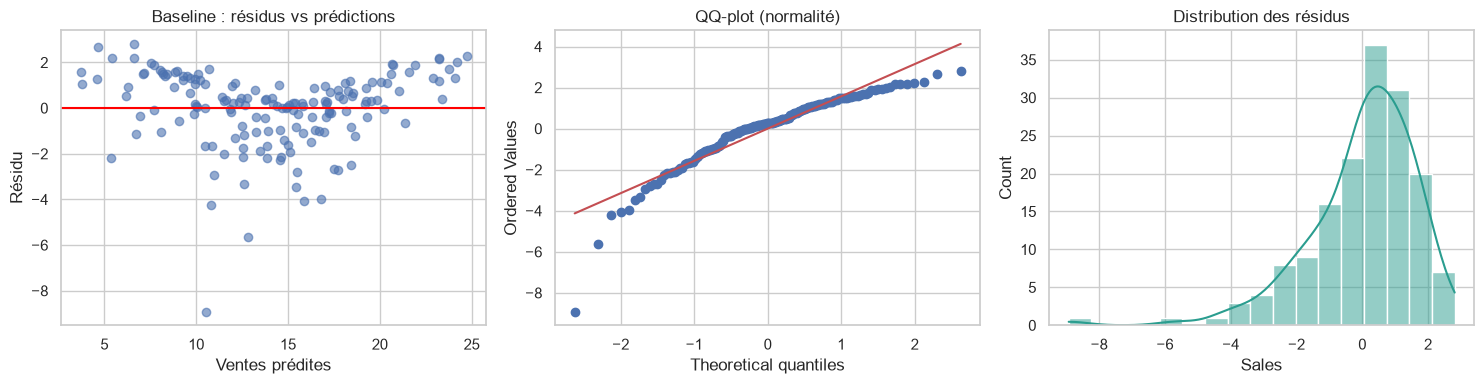

Shapiro-Wilk : W = 0.896, p = 0.0000   (p > 0,05 → résidus compatibles avec une loi normale)
Spearman |résidus| vs prédictions : rho = -0.114, p = 0.1502   (p < 0,05 → variance non constante)


In [39]:
residual_diagnostics(baseline, X_train, y_train, "Baseline")

**Lecture** : les résidus dessinent une **courbe en « U »** (le modèle surestime aux extrémités, sous-estime au milieu) et le QQ-plot s'écarte de la droite. Le modèle de base **rate une structure** : la relation n'est pas purement linéaire et additive. Cela rejoint l'indice de synergie (H1) et suggère aussi des **rendements décroissants** (H2) : on y revient en section 9.

## 8. Sélection de variables — faut-il garder Newspaper ?
On croise **trois preuves indépendantes** avant de décider.

**Preuve 1 : significativité statistique** (section 7).

In [40]:
table["p_value"].rename("p-value").to_frame()

,p-value
intercept,2.202e-14
TV,8.166e-64
Radio,1.016e-43
Newspaper,6.958e-01


**Preuve 2 : performance prédictive** — le modèle s'améliore-t-il avec Newspaper ? (validation croisée)

In [41]:
def keep(*names):
    # Modèle linéaire qui n'utilise que les colonnes indiquées
    return make_pipeline(FunctionTransformer(lambda d: d[list(names)]), LinearRegression())


pd.DataFrame(
    [
        cv_scores(keep("TV", "Radio", "Newspaper"), "TV + Radio + Newspaper"),
        cv_scores(keep("TV", "Radio"), "TV + Radio"),
        cv_scores(keep("TV"), "TV seule"),
    ]
)

,R² CV moyen,R² CV écart-type,RMSE CV moyen
TV + Radio + Newspaper,0.882,0.052,1.664
TV + Radio,0.884,0.052,1.649
TV seule,0.551,0.125,3.285


**Preuve 3 : importance par permutation** — de combien le R² chute-t-il si on *mélange au hasard* une colonne du jeu de test ? (plus la chute est grande, plus la variable compte)

In [42]:
perm = permutation_importance(baseline, X_test, y_test, n_repeats=30, random_state=RANDOM_STATE, scoring="r2")
importance = pd.DataFrame({"chute de R²": perm.importances_mean, "écart-type": perm.importances_std}, index=CHANNELS)
importance.sort_values("chute de R²", ascending=False)

,chute de R²,écart-type
TV,1.142,0.168
Radio,0.450,0.061
Newspaper,-0.001,0.001


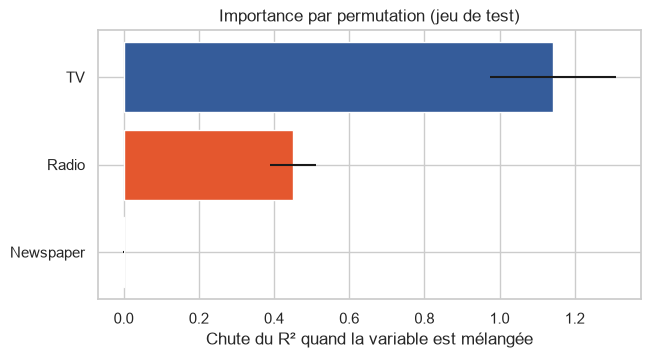

In [43]:
ordered = importance.sort_values("chute de R²")
plt.figure(figsize=(7, 3.5))
plt.barh(ordered.index, ordered["chute de R²"], xerr=ordered["écart-type"], color=[COLORS[c] for c in ordered.index])
plt.xlabel("Chute du R² quand la variable est mélangée")
plt.title("Importance par permutation (jeu de test)")
plt.show()

### Décision
| Preuve | Résultat pour Newspaper |
|---|---|
| p-value | ≫ 0,05 → effet non significatif |
| Validation croisée | aucun gain (R² identique avec ou sans) |
| Importance par permutation | ≈ 0 |
| Corrélation partielle | ≈ 0 une fois la radio contrôlée |

**Newspaper est retiré du modèle.** C'est aussi un résultat **business** : le budget presse n'a pas d'effet mesurable sur les ventes dans ces données. (La sélection est écrite dans `configs/config.yaml` → `features.selected`.)

## 9. Transformation des variables (feature engineering)
Deux hypothèses issues de l'exploration :
- **H1 — synergie** : l'effet de la TV dépend du budget radio → on ajoute **TV × Radio**.
- **H2 — rendements décroissants** : chaque dollar TV supplémentaire rapporte moins que le précédent → on ajoute **TV²** (un coefficient négatif traduirait la saturation).

On les teste **un par un**, en validation croisée, avec la fonction de production `add_engineered_features`.

In [44]:
# Aperçu des variables fabriquées par la fonction de production
add_engineered_features(X_train, selected=["TV", "Radio"], interaction=True, quadratic=["TV"]).head()

,TV,Radio,TV_x_Radio,TV_sq
79,116.0,7.7,893.20,13456.00
197,177.0,9.3,1646.10,31329.00
38,43.1,26.7,1150.77,1857.61
24,62.3,12.6,784.98,3881.29
122,224.0,2.4,537.60,50176.00


In [45]:
def engineered(selected, interaction, quadratic):
    return make_pipeline(
        FunctionTransformer(
            add_engineered_features,
            kw_args={"selected": selected, "interaction": interaction, "quadratic": quadratic},
        ),
        LinearRegression(),
    )


candidates = {
    "M0 · TV + Radio": engineered(["TV", "Radio"], False, []),
    "M1 · + TV×Radio (H1)": engineered(["TV", "Radio"], True, []),
    "M2 · + TV² (H2)": engineered(["TV", "Radio"], True, ["TV"]),
    "M3 · + Radio²": engineered(["TV", "Radio"], True, ["TV", "Radio"]),
    "M4 · M2 avec Newspaper": engineered(CHANNELS, True, ["TV"]),
}
results_fe = pd.DataFrame([cv_scores(model, name) for name, model in candidates.items()])
results_fe

,R² CV moyen,R² CV écart-type,RMSE CV moyen
M0 · TV + Radio,0.884,0.052,1.649
M1 · + TV×Radio (H1),0.962,0.023,0.943
M2 · + TV² (H2),0.983,0.014,0.613
M3 · + Radio²,0.983,0.014,0.614
M4 · M2 avec Newspaper,0.981,0.013,0.651


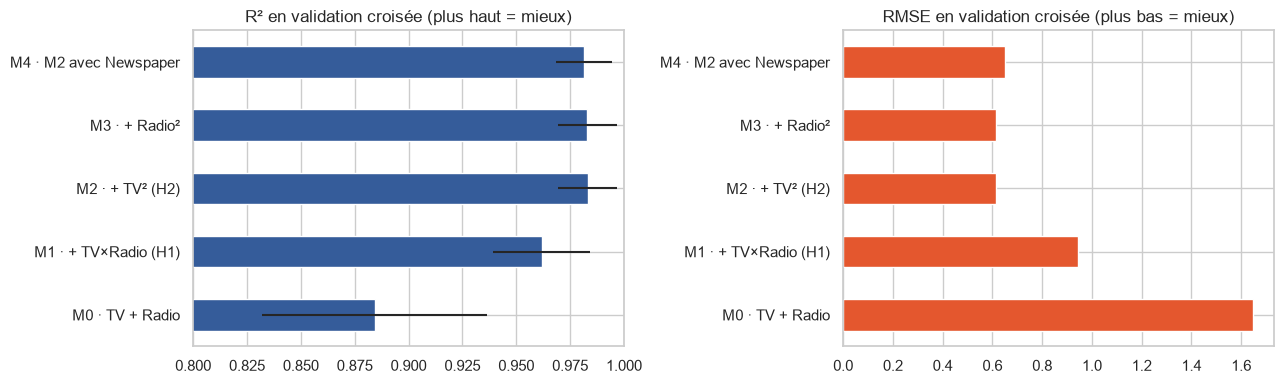

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
results_fe["R² CV moyen"].plot.barh(ax=axes[0], color="#355c9a", xerr=results_fe["R² CV écart-type"])
axes[0].set(title="R² en validation croisée (plus haut = mieux)", xlim=(0.8, 1.0))
results_fe["RMSE CV moyen"].plot.barh(ax=axes[1], color="#e4572e")
axes[1].set(title="RMSE en validation croisée (plus bas = mieux)")
plt.tight_layout()
plt.show()

**Lecture**
- **M1** (synergie) fait passer le R² d'environ 0,88 à environ 0,96 : H1 est **confirmée**, c'est le plus gros gain.
- **M2** (TV²) apporte encore un gain net : H2 est **confirmée** (rendements décroissants de la TV).
- **M3** (Radio²) n'améliore pas : pas de saturation mesurable pour la radio dans la plage observée.
- **M4** (réintégrer Newspaper) n'apporte rien : la sélection de la section 8 est **confirmée**.

On retient **M2** : `Sales = b0 + b1·TV + b2·Radio + b3·TV×Radio + b4·TV²`. Vérifions ses coefficients.

In [47]:
X_train_fe = add_engineered_features(X_train, ["TV", "Radio"], interaction=True, quadratic=["TV"])
table_fe, summary_fe = ols_summary(X_train_fe, y_train)
table_fe

,coef,std_err,t,p_value,ci_low,ci_high
intercept,5.076e+00,2.155e-01,23.555,4.409e-53,4.651e+00,5.502e+00
TV,5.151e-02,2.484e-03,20.737,1.469e-46,4.660e-02,5.641e-02
Radio,3.674e-02,6.671e-03,5.508,1.475e-07,2.357e-02,4.992e-02
TV_x_Radio,1.065e-03,3.880e-05,27.445,2.176e-61,9.882e-04,1.142e-03
TV_sq,-1.105e-04,7.713e-06,-14.327,3.462e-30,-1.257e-04,-9.527e-05


In [48]:
pd.Series(summary_fe)

n             1.600e+02
r2            9.852e-01
adj_r2        9.848e-01
f_stat        2.579e+03
f_p_value    1.214e-140
dtype: float64

**Interprétation des coefficients**
- `TV_x_Radio` **> 0** et significatif : **chaque dollar de radio rend la TV plus efficace** (et inversement) → synergie.
- `TV_sq` **< 0** et significatif : la contribution marginale de la TV **diminue** quand son budget augmente → saturation.
- `TV` et `Radio` : effets « de base » ; **l'effet réel d'un canal dépend du niveau des autres** (on le quantifie en section 12).

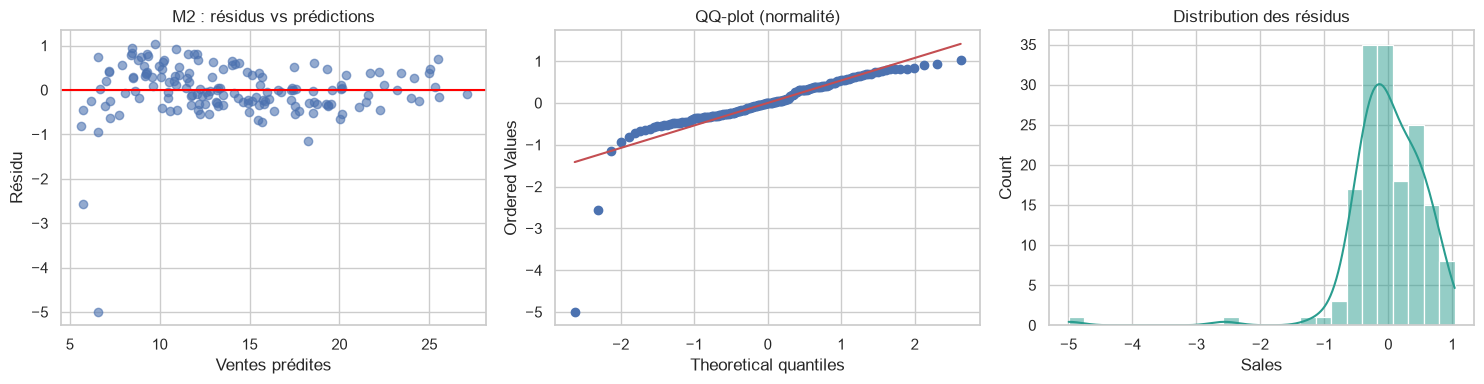

Shapiro-Wilk : W = 0.749, p = 0.0000   (p > 0,05 → résidus compatibles avec une loi normale)
Spearman |résidus| vs prédictions : rho = -0.266, p = 0.0007   (p < 0,05 → variance non constante)


In [49]:
# Les résidus ont-ils maintenant l'allure d'un bruit ?
m2 = candidates["M2 · + TV² (H2)"].fit(X_train, y_train)
residual_diagnostics(m2, X_train, y_train, "M2")

**Lecture honnête**
- ✅ La courbe en « U » a **disparu** et les résidus sont environ **5 fois plus petits** (échelle ± 1 contre ± 8 pour le modèle de base) : le modèle capte maintenant la structure des données.
- ⚠️ Le test de Shapiro-Wilk est pourtant encore rejeté et la variance n'est pas parfaitement constante. Le graphique en donne la raison : **deux campagnes** (résidus de −5 et −2,6) sont très en dessous des autres. Regardons-les.

In [50]:
# Les 3 plus fortes surestimations du modèle sur le jeu d'entraînement
residuals_m2 = y_train - m2.predict(X_train)
worst = residuals_m2.sort_values().head(3).index
X_train.loc[worst].assign(Sales=y_train[worst], prédit=m2.predict(X_train.loc[worst]), résidu=residuals_m2[worst])

,TV,Radio,Newspaper,Sales,prédit,résidu
130,0.7,39.6,8.7,1.6,6.597,-4.997
155,4.1,11.6,5.7,3.2,5.763,-2.563
41,177.0,33.4,38.7,17.1,18.254,-1.154


**Explication** : ces deux campagnes ont un budget **TV quasi nul** (0,7 et 4,1 k$). Le modèle prévoit alors ≈ 6 k unités alors que les ventes réelles sont de 1,6 et 3,2. La forme quadratique ne descend pas assez bas quand la TV est presque absente : **le modèle est moins fiable pour des budgets TV très faibles** (2 campagnes sur 160). Ces points sont réels, on les **garde** ; mais vérifions que les résultats n'en dépendent pas.

In [51]:
# Test de robustesse : on réentraîne SANS ces 2 campagnes, puis on compare coefficients et R² sur le test
mask = ~X_train.index.isin(worst[:2])
m2_robust = engineered(["TV", "Radio"], True, ["TV"]).fit(X_train[mask], y_train[mask])

pd.DataFrame(
    {
        "avec toutes les campagnes": [*m2.named_steps["linearregression"].coef_, m2.score(X_test, y_test)],
        "sans les 2 atypiques": [*m2_robust.named_steps["linearregression"].coef_, m2_robust.score(X_test, y_test)],
    },
    index=["TV", "Radio", "TV×Radio", "TV²", "R² test"],
)

,avec toutes les campagnes,sans les 2 atypiques
TV,5.151e-02,4.614e-02
Radio,3.674e-02,4.316e-02
TV×Radio,1.065e-03,1.031e-03
TV²,-1.105e-04,-9.324e-05
R² test,9.885e-01,9.874e-01


**Conclusion** : les coefficients bougent modestement et le **R² test reste quasiment identique** : le modèle est **stable**, ses prévisions ne dépendent pas de ces deux points. En revanche, les p-values et intervalles de confiance de l'OLS supposent des résidus normaux : ils sont **indicatifs** (la synergie et la saturation restent toutefois très significatives, p-values minuscules). Pour cette raison, l'API ne renvoie pas d'intervalle de prédiction.

## 10. Comparaison avec des modèles plus complexes
Avant de valider M2, vérifions qu'un modèle « boîte noire » ne ferait pas nettement mieux.

In [52]:
challengers = {
    "Régression linéaire M2 (retenue)": candidates["M2 · + TV² (H2)"],
    "Polynomial degré 2 + Ridge": make_pipeline(PolynomialFeatures(2, include_bias=False), StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 20))),
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingRegressor(random_state=RANDOM_STATE),
}
comparison_models = pd.DataFrame([cv_scores(model, name) for name, model in challengers.items()])
comparison_models

,R² CV moyen,R² CV écart-type,RMSE CV moyen
Régression linéaire M2 (retenue),0.983,0.014,0.613
Polynomial degré 2 + Ridge,0.981,0.013,0.658
Random Forest,0.969,0.012,0.863
Gradient Boosting,0.970,0.012,0.845


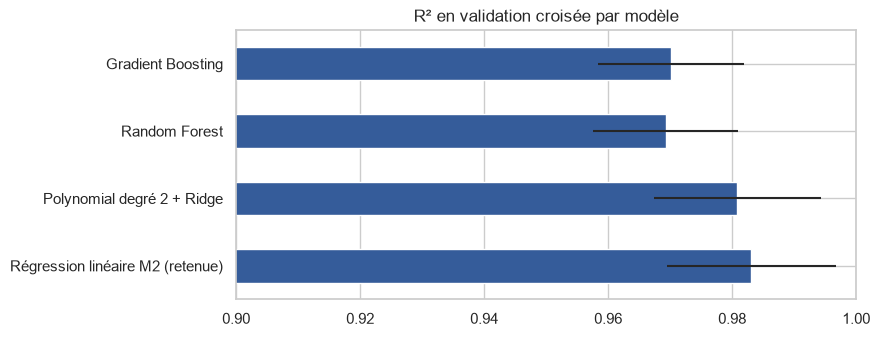

In [53]:
comparison_models["R² CV moyen"].plot.barh(figsize=(8, 3.5), color="#355c9a", xerr=comparison_models["R² CV écart-type"])
plt.xlim(0.9, 1.0)
plt.title("R² en validation croisée par modèle")
plt.show()

### Choix du modèle final : la régression linéaire M2
La régression M2 fait **aussi bien** que le polynôme + Ridge et **mieux** que les modèles d'arbres (RMSE ≈ 0,61 contre ≈ 0,85) : sur un jeu de 200 lignes à relation lisse, les modèles complexes n'ont rien à apporter. On s'appuie aussi sur d'autres critères :
1. **Interprétable** : chaque coefficient a un sens métier (indispensable pour conseiller un directeur marketing).
2. **Extrapole correctement** : un Random Forest renvoie une valeur *constante* au-delà du budget maximal vu ; le polynôme garde une forme logique.
3. **Simple et rapide** : 5 coefficients, entraînement instantané, modèle de quelques Ko.
4. **Fiable pour les simulations** (« et si j'augmente la TV de 10 % ? ») car sa réponse est lisse et prévisible.

## 11. Modèle final : entraînement et évaluation honnête
On utilise ici le **pipeline de production** (`build_pipeline`, piloté par `configs/config.yaml`) : même code, même sélection de variables.

In [54]:
final_model = build_pipeline(config).fit(X_train, y_train)
fit_and_score(final_model, "Modèle final").to_frame()

,Modèle final
R² train,0.985
RMSE train,0.620
MAE train,0.399
R² test,0.989
RMSE test,0.602
MAE test,0.497


**Lecture** : les scores sur **test** (jamais vu) sont proches de ceux sur **train** → pas de surapprentissage. Le R² dit que le modèle explique environ 98-99 % de la variabilité des ventes ; le RMSE/MAE donne l'erreur typique en milliers d'unités.

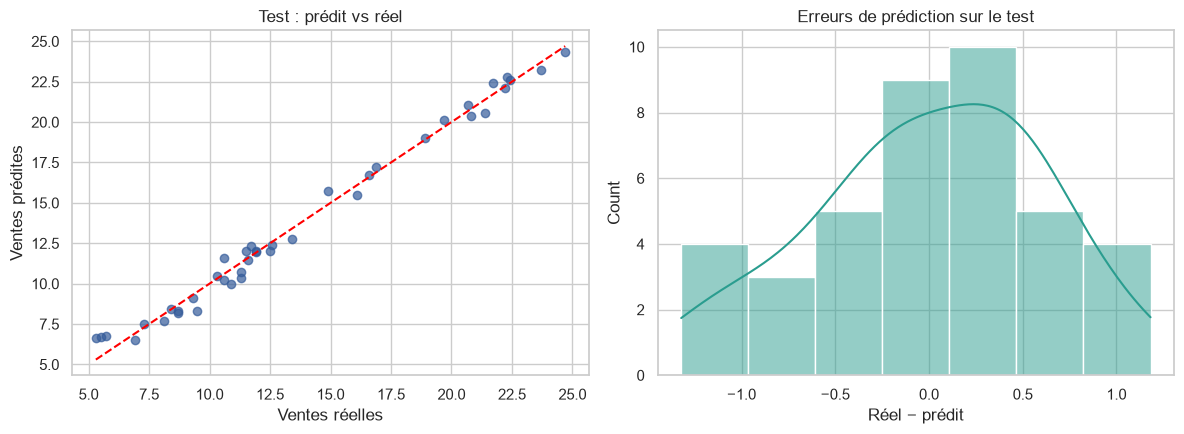

In [55]:
# Prédictions vs réalité sur le jeu de test : les points doivent suivre la diagonale
pred_test = final_model.predict(X_test)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(y_test, pred_test, alpha=0.7, color="#355c9a")
lims = [min(y_test.min(), pred_test.min()), max(y_test.max(), pred_test.max())]
axes[0].plot(lims, lims, color="red", linestyle="--")
axes[0].set(title="Test : prédit vs réel", xlabel="Ventes réelles", ylabel="Ventes prédites")
sns.histplot(y_test - pred_test, kde=True, ax=axes[1], color="#2a9d8f")
axes[1].set(title="Erreurs de prédiction sur le test", xlabel="Réel − prédit")
plt.tight_layout()
plt.show()

In [56]:
# Analyse d'erreurs : où le modèle se trompe-t-il le plus ?
errors = X_test.assign(réel=y_test, prédit=pred_test)
errors["erreur"] = errors["prédit"] - errors["réel"]
errors["erreur %"] = errors["erreur"] / errors["réel"] * 100
errors.reindex(errors["erreur"].abs().sort_values(ascending=False).index).head(5)

,TV,Radio,Newspaper,réel,prédit,erreur,erreur %
78,5.4,29.9,9.4,5.3,6.622,1.322,24.940
56,7.3,28.1,41.4,5.5,6.697,1.197,21.770
66,31.5,24.6,2.2,9.5,8.318,-1.182,-12.440
132,8.4,27.2,2.1,5.7,6.744,1.044,18.314
9,199.8,2.6,21.2,10.6,11.605,1.005,9.480


**Lecture** : les plus fortes erreurs **relatives** (jusqu'à ≈ 25 %) touchent des campagnes à **faibles ventes** (≈ 5 k unités) : une erreur de 1,3 k pèse lourd quand le total est petit. En valeur absolue, aucune erreur ne dépasse ≈ 1,3 k unités sur le jeu de test.

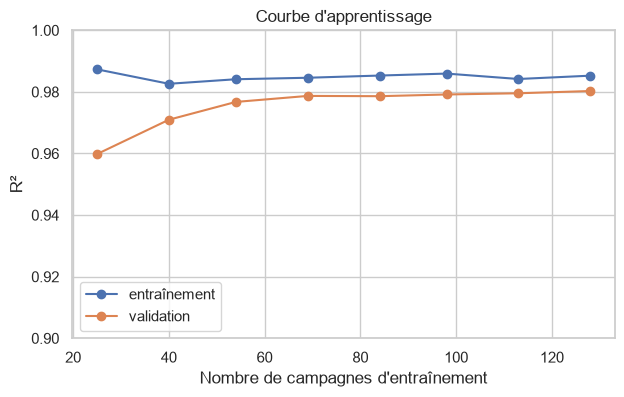

In [57]:
# Courbe d'apprentissage : le modèle bénéficierait-il de plus de données ?
sizes, train_scores, val_scores = learning_curve(
    build_pipeline(config), X_train, y_train, cv=5, train_sizes=np.linspace(0.2, 1.0, 8), scoring="r2", random_state=RANDOM_STATE, shuffle=True
)
plt.figure(figsize=(7, 4))
plt.plot(sizes, train_scores.mean(axis=1), "o-", label="entraînement")
plt.plot(sizes, val_scores.mean(axis=1), "o-", label="validation")
plt.xlabel("Nombre de campagnes d'entraînement")
plt.ylabel("R²")
plt.ylim(0.9, 1.0)
plt.legend()
plt.title("Courbe d'apprentissage")
plt.show()

**Lecture** : la courbe de validation rejoint presque celle d'entraînement et se stabilise vers 70 campagnes, à un niveau élevé (≈ 0,98) → le modèle est **bien dimensionné** (ni sous-apprentissage, ni surapprentissage) et plus de données n'apporteraient qu'un gain marginal.

## 12. Analyse d'impact publicitaire et recommandations
C'est le cœur du projet : **que se passe-t-il quand on change les budgets ?** On part d'une campagne « moyenne » (budgets moyens du jeu de données) et on simule.

In [58]:
# Campagne de référence = budgets moyens
base = X.mean().to_dict()
print("Budgets moyens (k$) :", {k: round(v, 1) for k, v in base.items()})
print(f"Ventes prédites : {predict_sales(final_model, base):.2f} k unités")

Budgets moyens (k$) : {'TV': 147.0, 'Radio': 23.3, 'Newspaper': 30.6}
Ventes prédites : 14.76 k unités


### 12.1 Effet marginal : que rapporte 1 000 $ de plus sur chaque canal ?

In [59]:
effects = marginal_effects(final_model, base, step=1.0)  # ventes en plus pour +1 k$, les autres canaux fixes
impact = pd.DataFrame(
    {
        "ventes en plus (k unités) pour +1 k$": effects,
        "unités vendues en plus pour +1 000 $": {k: round(v * 1000) for k, v in effects.items()},
    }
)
impact

,ventes en plus (k unités) pour +1 k$,unités vendues en plus pour +1 000 $
TV,0.044,44
Radio,0.193,193
Newspaper,0.000,0


**Lecture** : au budget moyen, **1 000 $ en radio rapportent environ 4 fois plus d'unités que 1 000 $ en TV**, et **0 pour la presse**. Mais attention : l'effet marginal dépend du niveau des budgets (synergie et saturation), ce que montrent les graphiques suivants.

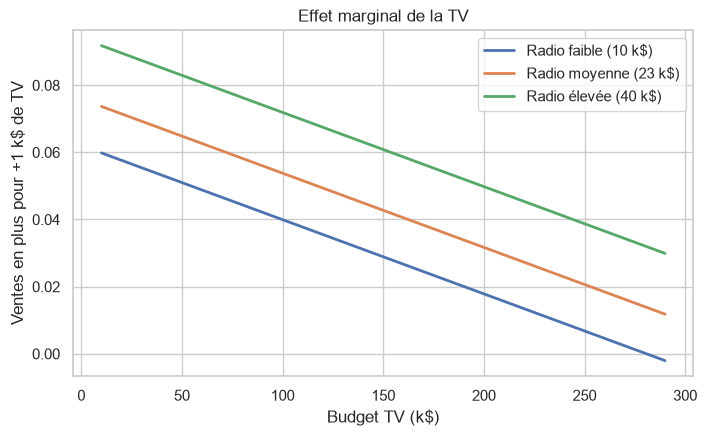

In [60]:
# L'effet marginal de la TV selon son niveau de budget, pour trois niveaux de radio : rendements décroissants + synergie
tv_grid = np.arange(10, 291, 10)
fig, ax = plt.subplots(figsize=(8, 4.5))
for label, radio in {"Radio faible (10 k$)": 10, "Radio moyenne (23 k$)": 23, "Radio élevée (40 k$)": 40}.items():
    marginal_tv = [marginal_effects(final_model, {"TV": t, "Radio": radio, "Newspaper": base["Newspaper"]})["TV"] for t in tv_grid]
    ax.plot(tv_grid, marginal_tv, label=label, linewidth=2)
ax.set(xlabel="Budget TV (k$)", ylabel="Ventes en plus pour +1 k$ de TV", title="Effet marginal de la TV")
ax.legend()
plt.show()

**Lecture** : chaque courbe **descend** (rendements décroissants : plus on dépense en TV, moins le dollar suivant rapporte) et les courbes sont **décalées vers le haut** quand la radio augmente (synergie : plus il y a de radio, plus la TV est efficace).

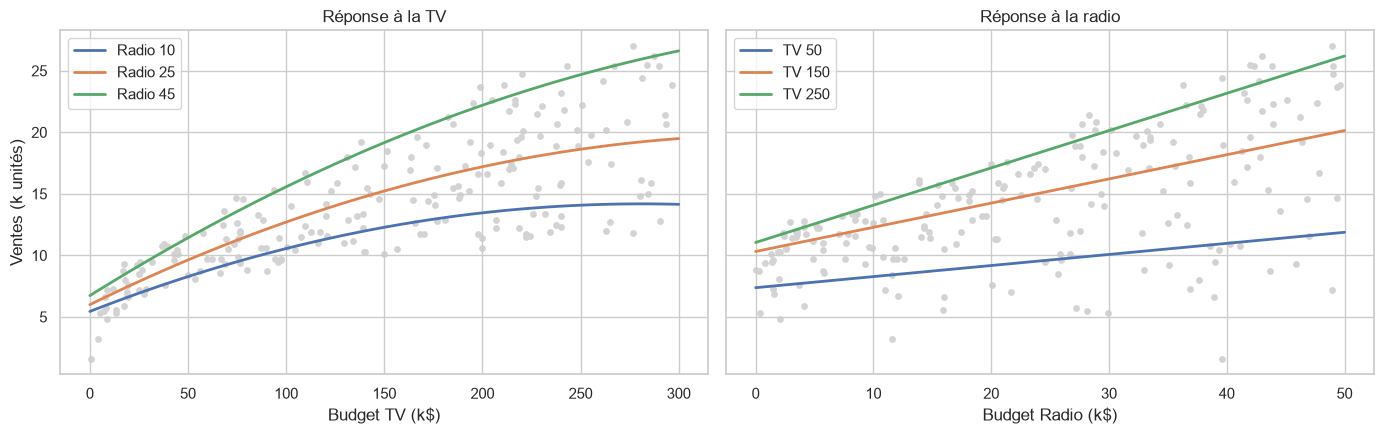

In [61]:
# Courbes de réponse : ventes selon le budget TV, pour trois niveaux de radio (points gris = campagnes réelles)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)

grid_tv = pd.DataFrame({"TV": np.linspace(0, 300, 100)})
for label, radio in {"Radio 10": 10, "Radio 25": 25, "Radio 45": 45}.items():
    curve = final_model.predict(grid_tv.assign(Radio=radio, Newspaper=base["Newspaper"]))
    axes[0].plot(grid_tv["TV"], curve, linewidth=2, label=label)
axes[0].scatter(df["TV"], df[TARGET], color="lightgray", s=15, zorder=0)
axes[0].set(xlabel="Budget TV (k$)", ylabel="Ventes (k unités)", title="Réponse à la TV")
axes[0].legend()

grid_radio = pd.DataFrame({"Radio": np.linspace(0, 50, 100)})
for label, tv in {"TV 50": 50, "TV 150": 150, "TV 250": 250}.items():
    curve = final_model.predict(grid_radio.assign(TV=tv, Newspaper=base["Newspaper"]))
    axes[1].plot(grid_radio["Radio"], curve, linewidth=2, label=label)
axes[1].scatter(df["Radio"], df[TARGET], color="lightgray", s=15, zorder=0)
axes[1].set(xlabel="Budget Radio (k$)", title="Réponse à la radio")
axes[1].legend()
plt.tight_layout()
plt.show()

### 12.2 Scénarios « et si… ? »

In [62]:
# +10 % sur un canal (ou plusieurs), les autres inchangés
scenarios = {
    "TV +10 %": {"TV": 10},
    "Radio +10 %": {"Radio": 10},
    "Presse +10 %": {"Newspaper": 10},
    "Presse supprimée (-100 %)": {"Newspaper": -100},
    "TV +10 % et Radio +10 %": {"TV": 10, "Radio": 10},
}
rows = {}
for name, change in scenarios.items():
    result = what_if(final_model, base, change)
    extra_budget = sum(base[k] * pct / 100 for k, pct in change.items())  # variation du budget total (k$)
    result["budget en plus (k$)"] = extra_budget
    result["ventes en plus par k$"] = result["delta"] / extra_budget
    rows[name] = result
pd.DataFrame(rows).T[["budget en plus (k$)", "delta", "delta_pct", "ventes en plus par k$"]]

,budget en plus (k$),delta,delta_pct,ventes en plus par k$
TV +10 %,14.704,0.620,4.200,0.042
Radio +10 %,2.326,0.450,3.047,0.193
Presse +10 %,3.055,0.000,0.000,0.000
Presse supprimée (-100 %),-30.554,0.000,0.000,-0.000
TV +10 % et Radio +10 %,17.031,1.106,7.495,0.065


In [63]:
# Scénario de réallocation : déplacer 20 k$ de la presse vers la radio, SANS changer le budget total
shift = 20
shifted = {**base, "Newspaper": base["Newspaper"] - shift, "Radio": base["Radio"] + shift}
before, after = predict_sales(final_model, base), predict_sales(final_model, shifted)
print(f"Avant : {before:.2f} k unités | Après : {after:.2f} k unités | Gain : {after - before:+.2f} ({(after / before - 1) * 100:+.1f} %)")
print(f"Budget total inchangé : {sum(base.values()):.1f} k$ → {sum(shifted.values()):.1f} k$")

Avant : 14.76 k unités | Après : 18.62 k unités | Gain : +3.87 (+26.2 %)
Budget total inchangé : 200.9 k$ → 200.9 k$


### 12.3 Optimisation : la meilleure répartition d'un budget donné
`optimize_budget` teste **toutes** les répartitions possibles (grille au pas de 1 k$) à budget total constant et garde celle qui maximise les ventes prédites. Les budgets sont **plafonnés aux maxima observés** (on ne veut pas extrapoler là où le modèle n'a aucune donnée).

In [64]:
total = sum(base.values())          # budget total moyen
upper = X.max().to_dict()           # plafonds = budgets maximaux observés
best = optimize_budget(final_model, total, CHANNELS, upper, step=1.0)

options = pd.DataFrame(
    {
        "Répartition actuelle (moyenne)": base,
        "Répartition égale (1/3 chacun)": {ch: total / 3 for ch in CHANNELS},
        "Répartition optimale": best["allocation"],
    }
).T
options["Ventes prédites"] = [predict_sales(final_model, row[CHANNELS].to_dict()) for _, row in options.iterrows()]
options["Gain vs actuel"] = options["Ventes prédites"] - options.loc["Répartition actuelle (moyenne)", "Ventes prédites"]
options

,TV,Radio,Newspaper,Ventes prédites,Gain vs actuel
Répartition actuelle (moyenne),147.042,23.264,30.554,14.758,0.000
Répartition égale (1/3 chacun),66.954,66.954,66.954,15.263,0.505
Répartition optimale,151.000,49.000,0.861,20.014,5.255


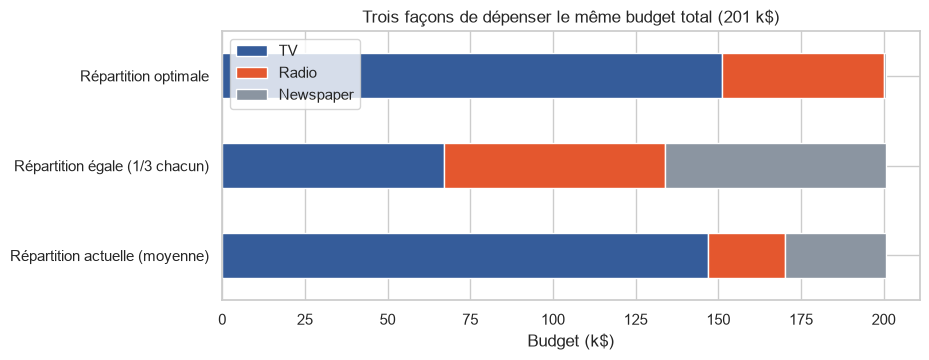

In [65]:
options[CHANNELS].plot.barh(stacked=True, figsize=(9, 3.5), color=[COLORS[c] for c in CHANNELS])
plt.xlabel("Budget (k$)")
plt.title(f"Trois façons de dépenser le même budget total ({total:.0f} k$)")
plt.show()

**Lecture** : à budget identique, la répartition optimale **supprime la presse** et **concentre l'argent sur la TV et la radio**, avec un gain de ventes important. La radio est portée à son **plafond observé** : le modèle indique que la radio est sous-exploitée, mais **ne peut pas dire** ce qui se passerait au-delà de ce qu'on a déjà vu.

In [66]:
# Comment la répartition optimale évolue-t-elle quand le budget total augmente ?
totals = np.arange(50, 351, 25)
rows = []
for t in totals:
    optimum = optimize_budget(final_model, t, CHANNELS, upper, step=1.0)
    scaled_current = {ch: base[ch] * t / total for ch in CHANNELS}  # même mix que l'actuel, à l'échelle
    rows.append({**optimum["allocation"], "total": t, "ventes optimales": optimum["predicted_sales"],
                 "ventes mix actuel": predict_sales(final_model, scaled_current)})
path = pd.DataFrame(rows).set_index("total")
path

,TV,Radio,Newspaper,ventes optimales,ventes mix actuel
total,,,,,
50,29.0,21.0,0.0,7.897,7.252
75,40.0,35.0,0.0,9.737,8.398
100,52.0,48.0,0.0,11.877,9.583
125,76.0,49.0,0.0,14.119,10.807
150,101.0,49.0,0.0,16.222,12.070
175,126.0,49.0,0.0,18.187,13.371
200,151.0,49.0,0.0,20.014,14.711
225,176.0,49.0,0.0,21.702,16.091
250,201.0,49.0,0.0,23.253,17.509


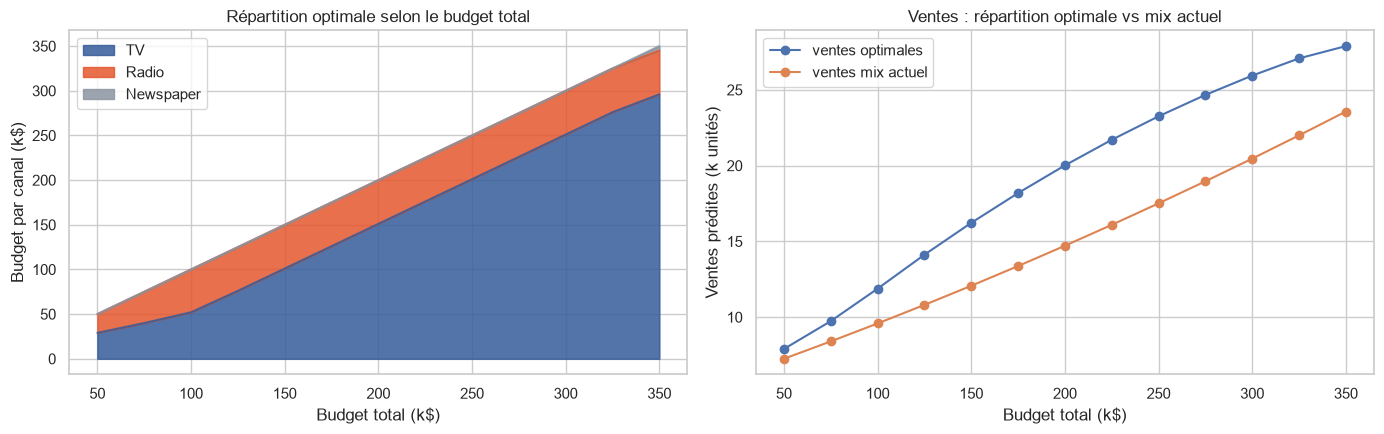

In [67]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
path[CHANNELS].plot.area(ax=axes[0], color=[COLORS[c] for c in CHANNELS], alpha=0.85)
axes[0].set(title="Répartition optimale selon le budget total", xlabel="Budget total (k$)", ylabel="Budget par canal (k$)")
path[["ventes optimales", "ventes mix actuel"]].plot(ax=axes[1], marker="o")
axes[1].set(title="Ventes : répartition optimale vs mix actuel", xlabel="Budget total (k$)", ylabel="Ventes prédites (k unités)")
plt.tight_layout()
plt.show()

**Lecture** : la **radio** est servie en priorité : elle atteint son **plafond observé (≈ 49 k$) dès un budget total d'environ 100 k$**. Ensuite, **chaque dollar supplémentaire va à la TV**, jusqu'à son propre plafond. La presse n'apparaît (≈ 5 k$ à 350 k$ de budget) que parce que le budget total doit bien être dépensé quelque part : elle n'ajoute aucune vente. L'écart entre « optimal » et « mix actuel » est le **gain potentiel** d'une meilleure allocation (environ +4 à +6 k unités sur la plage 150–350 k$).

In [68]:
# Synthèse chiffrée générée automatiquement à partir des résultats ci-dessus
gain = options.loc["Répartition optimale", "Gain vs actuel"]
current_sales = options.loc["Répartition actuelle (moyenne)", "Ventes prédites"]
print("SYNTHÈSE POUR LA DIRECTION MARKETING")
print("-" * 60)
print(f"1. Modèle : R² test = {metrics(y_test, final_model.predict(X_test))['R²']:.3f}, erreur typique (RMSE) = {metrics(y_test, final_model.predict(X_test))['RMSE']:.2f} k unités.")
print(f"2. À budget moyen, +1 000 $ rapportent : Radio ≈ {effects['Radio'] * 1000:.0f} unités, TV ≈ {effects['TV'] * 1000:.0f} unités, Presse ≈ {effects['Newspaper'] * 1000:.0f} unité.")
print(f"3. Radio plus rentable que TV au dollar : x{effects['Radio'] / effects['TV']:.1f}.")
print(f"4. Réallouer le budget moyen ({total:.0f} k$) comme suit : " + ", ".join(f"{k} {v:.0f} k$" for k, v in best['allocation'].items()))
print(f"   → ventes prévues {best['predicted_sales']:.1f} contre {current_sales:.1f} aujourd'hui ({gain:+.1f} k unités, {gain / current_sales * 100:+.0f} %), SANS dépenser plus.")

SYNTHÈSE POUR LA DIRECTION MARKETING
------------------------------------------------------------
1. Modèle : R² test = 0.989, erreur typique (RMSE) = 0.60 k unités.
2. À budget moyen, +1 000 $ rapportent : Radio ≈ 193 unités, TV ≈ 44 unités, Presse ≈ 0 unité.
3. Radio plus rentable que TV au dollar : x4.4.
4. Réallouer le budget moyen (201 k$) comme suit : TV 151 k$, Radio 49 k$, Newspaper 1 k$
   → ventes prévues 20.0 contre 14.8 aujourd'hui (+5.3 k unités, +36 %), SANS dépenser plus.


## Recommandations marketing

1. **Arrêter ou réduire fortement le budget presse.** Aucun effet mesurable (p-value élevée, aucun gain prédictif, corrélation brute due à la radio). Chaque dollar retiré de la presse et placé ailleurs est un gain net.
2. **Investir davantage en radio, jusqu'à ce que les données le permettent.** C'est le canal le plus rentable au dollar près, et il **amplifie** la TV. Mais les budgets radio observés ne dépassent pas ≈ 50 k$ : au-delà, nous manquons de données → **tester progressivement** (par paliers) avant de généraliser.
3. **Garder la TV comme canal d'appui, sans la surdimensionner.** Elle est le principal moteur de ventes en volume, mais ses **rendements sont décroissants** : passé un certain niveau, le dollar suivant rapporte peu.
4. **Penser « mix » plutôt que « canaux isolés ».** TV et radio se renforcent mutuellement : réduire l'un affaiblit l'autre. Utiliser l'optimiseur de l'API pour répartir chaque budget annuel.
5. **Valider par expérimentation.** Ces résultats sont **corrélationnels** : un test contrôlé (par région ou par période) confirmerait la causalité avant un changement radical.

## Limites à garder en tête
- **200 campagnes** seulement et **aucune date** : pas de saisonnalité, de tendance ni d'effet retardé (une publicité agit parfois des semaines plus tard) ; un vrai suivi temporel permettrait d'aller plus loin.
- **Plage de validité** : les prévisions hors des budgets observés (TV > 296 k$, radio > 50 k$) sont des **extrapolations** non fiables (l'API les signale).
- **Budgets TV très faibles** : pour une TV quasi nulle, le modèle surestime les ventes (section 9) ; ne pas l'utiliser pour simuler la suppression totale de la TV.
- **Corrélation ≠ causalité** : le modèle décrit des associations observées, pas des effets prouvés.
- **Pas de coûts ni de marges** : on maximise les *ventes*, pas le *profit*.

## 13. Passage en production
Tout ce qui a été validé ici existe sous forme de code testé dans `src/sales_prediction/` :

| Étape du notebook | Module de production |
|---|---|
| Nettoyage (§3) | `data.py` |
| Feature engineering & pipeline (§9, §11) | `features.py` |
| Validation croisée et métriques (§6) | `evaluate.py` |
| Statistiques, effets marginaux, scénarios, optimisation (§7, §12) | `analysis.py` |
| Entraînement, quality gate, sérialisation | `train.py` |
| Chargement et inférence | `predict.py` |
| API REST + interface web | `api/` |

La cellule suivante lance l'entraînement **de production** depuis le notebook (équivalent de `uv run sales-train`) et crée `models/model.joblib`.

In [69]:
from sales_prediction.train import train

metadata = train(config)  # écrit models/model.joblib, models/metadata.json et data/processed/
print("Version du modèle :", metadata["model_version"])
print("Colonnes du modèle :", metadata["engineered_columns"])
pd.DataFrame(metadata["metrics"]).T

Version du modèle : 0.1.0-69104adc
Colonnes du modèle : ['TV', 'Radio', 'TV_x_Radio', 'TV_sq']


,r2_mean,r2_std,rmse_mean,rmse_std,r2,rmse,mae
cross_validation,0.983,0.014,0.613,0.267,NaN,NaN,NaN
test,NaN,NaN,NaN,NaN,0.989,0.602,0.497


**Étape suivante** : lancer l'API (`uv run uvicorn sales_prediction.api.main:create_app --factory --reload`), puis conteneuriser avec Docker et déployer sur Render (voir `README.md`).